# PaySim · Motif Finding
## Khánh — cycle, relay và hiệu chỉnh fan-in có kiểm chứng

**Dataset xuyên suốt:** PaySim, full graph **9.073.900 tài khoản / 6.362.620 giao dịch**.
Đỉnh là tài khoản, cạnh là giao dịch có hướng từ người gửi đến người nhận.

| Thành phần | Dữ liệu / ý nghĩa |
|---|---|
| Input | `data/processed/paysim/vertices.parquet`, `edges.parquet` |
| `type` | TRANSFER, CASH_OUT và các loại giao dịch mô phỏng khác |
| `step` | Giờ mô phỏng; không phải timestamp chính xác của từng giao dịch |
| `amount` | Số tiền theo đơn vị mô phỏng của PaySim; không tự gọi là USD |
| `isFraud` | Nhãn đối chiếu, không dùng để lọc relay |
| Output trong notebook | Baseline, hypothesis audit, validation grid, test metrics, TP/FP/FN và hình minh họa |

### Lộ trình trình bày

**Môi trường → toy → baseline cycle/relay → điều tra nguyên nhân → hiệu chỉnh fan-in → đánh giá test và phản ví dụ → review PageRank → kiểm chứng source.**

Toy và ví dụ PageRank là đồ thị nhỏ tự tạo để giải thích thuật toán, không phải các dataset thực nghiệm bổ sung. Phần review lý thuyết 3.3 được đặt ở phụ lục để mạch trình bày motif không bị gián đoạn.

### Các đầu việc của Khánh được giữ trong notebook

| Hạn | Nội dung |
|---|---|
| 21/9 | Học graph.find và toy cycle 3-node |
| 25/9 | Review 3.3 PageRank: toán, sink-node và ký hiệu |
| 28/9 | Final 3.3 |
| 30/9 | Draft Task 3 PaySim: cycle và relay >10.000 |
| 3/10 | Fix Task 3 PaySim theo tiêu chí review |

**Chạy:** chọn Windows `.venv\Scripts\python.exe` → **Restart Kernel → Run All**.
Notebook tự khởi tạo Spark `local[4]`, heap **6 GiB**. Không cần chạy notebook khác.
Các hình/bảng được nhúng vào file này; không xuất CSV/PNG/log vào repository. Runtime tạm nằm ngoài repo.
PASS tự động không thay phê duyệt của người review.

## 0 · Kiểm tra môi trường và input PaySim


In [1]:
from __future__ import annotations
import ast
import csv
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import subprocess
import sys
import tempfile
import time
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display
from graphframes import GraphFrame
from pyspark.sql import DataFrame, SparkSession, functions as F

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'requirements.txt').is_file() and (p / 'src').is_dir())
NOTEBOOK_PATH = REPO_ROOT / 'notebooks/03_khanh_PaySIM_motif.ipynb'
assert os.name == 'nt', 'Chọn Windows .venv; không chạy bằng WSL.'
assert sys.version_info[:2] == (3, 12), 'Cần Python 3.12.'
assert os.path.samefile(sys.executable, REPO_ROOT / '.venv/Scripts/python.exe'), 'Chọn .venv của repo.'
sys.path.insert(0, str(REPO_ROOT))
os.environ['PYTHONUTF8'] = '1'
os.environ['PYTHONIOENCODING'] = 'utf-8'
from src.common.spark_session import get_graph_session

for package, expected in [('pyspark','3.5.1'), ('graphframes-py','0.12.2')]:
    assert metadata.version(package) == expected, (package, metadata.version(package))
dependencies = subprocess.run([sys.executable, '-m', 'pip', 'check'], capture_output=True, text=True)
assert dependencies.returncode == 0, dependencies.stdout + dependencies.stderr
print(dependencies.stdout.strip())
required_inputs = ['data/processed/paysim/vertices.parquet', 'data/processed/paysim/edges.parquet', 'results/paysim/relay_candidates.csv']
for relative in required_inputs:
    assert (REPO_ROOT / relative).exists(), f'Thiếu dữ liệu: {relative}'
started_at = datetime.now(timezone.utc)
started_clock = time.perf_counter()
checks_passed = {}
plt.rcParams.update({'figure.dpi':110, 'font.family':'DejaVu Sans', 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})
print('Windows:', platform.platform())
print('Python:', sys.version.split()[0], '|', sys.executable)
print('Bắt đầu UTC:', started_at.isoformat())


No broken requirements found.
Windows: Windows-11-10.0.26300-SP0
Python: 3.12.10 | D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\.venv\Scripts\python.exe
Bắt đầu UTC: 2026-10-18T16:16:26.858080+00:00


Đầu vào đã được Task 1 xây thành Parquet. Các cell sau chỉ đọc full graph và chạy phần motif của Khánh. Trước khi tạo Spark, kiểm tra Windows Python 3.12, dependency và kernel của repo; sau khi tạo Spark, kiểm tra Java 17 thực sự được JVM sử dụng.


In [2]:
# Vẽ ngay trong notebook: nhãn cạnh đặt lệch khỏi mũi tên để dễ đọc.
def draw_graph(nodes, edges, title, positions=None, colors=None):
    if positions is None:
        angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, len(nodes), endpoint=False)
        positions = {node: (np.cos(angle), np.sin(angle)) for node, angle in zip(nodes, angles)}
    colors = colors or ['#2563eb'] * len(edges)
    fig, ax = plt.subplots(figsize=(10, 5))
    for index, (source, target, label) in enumerate(edges):
        start, end = np.array(positions[source]), np.array(positions[target])
        direction = end - start
        normal = np.array([-direction[1], direction[0]]) / np.linalg.norm(direction)
        label_position = (start + end) / 2 + 0.22 * normal
        source_padding = 55 if max(map(len, nodes[source].splitlines())) > 10 else 35
        target_padding = 55 if max(map(len, nodes[target].splitlines())) > 10 else 35
        ax.add_patch(FancyArrowPatch(
            start, end, arrowstyle='-|>', mutation_scale=19, linewidth=2,
            shrinkA=source_padding, shrinkB=target_padding,
            color=colors[index % len(colors)], connectionstyle='arc3,rad=0.04',
        ))
        ax.text(
            *label_position, label, ha='center', va='center', fontsize=9,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.95},
        )
    for node, label in nodes.items():
        ax.text(
            *positions[node], label, ha='center', va='center', color='#0f172a',
            bbox={'boxstyle': 'round,pad=0.7', 'facecolor': '#eff6ff', 'edgecolor': '#93c5fd'},
        )
    ax.set(xlim=(-1.6, 1.6), ylim=(-1.4, 1.5), title=title)
    ax.axis('off')
    plt.show()

runtime_temp = tempfile.TemporaryDirectory(prefix='graphguard-paysim-',ignore_cleanup_errors=True)
spark = get_graph_session('GraphGuard-Khanh-PaySim',driver_memory='6g',shuffle_partitions=8,
    extra_configs={'spark.master':'local[4]','spark.default.parallelism':'4',
                   'spark.ui.enabled':'false','spark.ui.showConsoleProgress':'false',
                   'spark.sql.warehouse.dir':(Path(runtime_temp.name)/'warehouse').as_uri()})
spark.sparkContext.setLogLevel('ERROR')
java_version = spark.sparkContext._jvm.java.lang.System.getProperty('java.version')
assert java_version.startswith('17.'), java_version
runtime = {'system':platform.system(),'python':platform.python_version(),'spark':spark.version,
    'graphframes':metadata.version('graphframes-py'),'java':java_version,
    'master':spark.sparkContext.master,'driver_memory':spark.sparkContext.getConf().get('spark.driver.memory'),
    'session_timezone':spark.conf.get('spark.sql.session.timeZone')}
runtime['dataset'] = 'PaySim'
display(pd.DataFrame([runtime]))
checks_passed['Windows Python 3.12 / JDK 17 / dependencies'] = True


,system,python,spark,graphframes,java,master,driver_memory,session_timezone,dataset
0,Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],6g,Asia/Saigon,PaySim


In [3]:
# Đọc đủ vertices/edges Parquet rồi tạo GraphFrame.
# Production: src/common/graph_utils.py

def load_graph(spark: SparkSession, data_dir: str) -> GraphFrame:
    """Load GraphFrame từ thư mục chứa vertices.parquet và edges.parquet."""
    data_path = Path(data_dir)
    vertices_path = data_path / "vertices.parquet"
    edges_path = data_path / "edges.parquet"

    if not vertices_path.exists():
        raise FileNotFoundError(f"Không tìm thấy vertices tại: {vertices_path}")
    if not edges_path.exists():
        raise FileNotFoundError(f"Không tìm thấy edges tại: {edges_path}")

    v_df = spark.read.parquet(str(vertices_path))
    e_df = spark.read.parquet(str(edges_path))
    return GraphFrame(v_df, e_df)


## 1 · Hiểu query cycle bằng toy graph

Query gán tên cho **đỉnh và cạnh**, tìm mọi cách gán khớp cấu trúc. Ba ID khác nhau loại self-loop và đường đóng chỉ đi qua hai tài khoản. A→B→C→A có ba điểm bắt đầu nên sinh ba dòng. Giữ `a` nhỏ nhất khử phép xoay, giữ nguyên chiều cạnh.


In [4]:
MOTIF_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)"


In [5]:
# Đầy đủ toy graph, truy vấn và kiểm chứng số phép xoay.
# Production: src/motif/toy_cycle.py

def build_toy_graph(spark: SparkSession) -> GraphFrame:
    """Tạo A → B → C → A, mỗi đỉnh và cạnh có thuộc tính để quan sát."""
    vertices = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'Alice'), ('B', 'Bob'), ('C', 'Carol') "
        "AS v(id, name)"
    )
    edges = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'B', 'transfer'), ('B', 'C', 'transfer'), "
        "('C', 'A', 'transfer') "
        "AS e(src, dst, kind)"
    )
    return GraphFrame(vertices, edges)

def find_three_node_cycles(graph: GraphFrame) -> DataFrame:
    """Chạy đúng motif đã giao và loại các đường đóng có đỉnh trùng nhau."""
    return (
        graph.find(MOTIF_PATTERN)
        .where(
            (F.col("a.id") != F.col("b.id"))
            & (F.col("b.id") != F.col("c.id"))
            & (F.col("c.id") != F.col("a.id"))
        )
    )

def cycle_ids(motifs: DataFrame) -> DataFrame:
    """Lấy ID đỉnh theo thứ tự chiều cạnh; mỗi dòng là một phép xoay."""
    return motifs.select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
    )

def run_demo(spark: SparkSession) -> dict:
    """Trả dữ liệu demo và kiểm tra số kết quả mong đợi trên toy graph."""
    graph = build_toy_graph(spark)
    matches = cycle_ids(find_three_node_cycles(graph))
    rows = sorted(tuple(row) for row in matches.collect())
    expected = [("A", "B", "C"), ("B", "C", "A"), ("C", "A", "B")]
    if rows != expected:
        raise AssertionError(f"Motif sai: mong đợi {expected}, nhận {rows}")

    # Chỉ giữ phép xoay bắt đầu ở ID nhỏ nhất, tránh đếm 1 chu trình 3 lần.
    unique = sorted(row for row in rows if row[0] == min(row))
    if unique != [("A", "B", "C")]:
        raise AssertionError(f"Chu trình duy nhất sai: {unique}")

    return {
        "status": "PASS",
        "pattern": MOTIF_PATTERN,
        "vertices": ["A", "B", "C"],
        "edges": [["A", "B"], ["B", "C"], ["C", "A"]],
        "raw_match_count": len(rows),
        "raw_matches": [list(row) for row in rows],
        "unique_cycle_count": len(unique),
        "unique_cycles": [list(row) for row in unique],
    }


,id,name
0,A,Alice
1,B,Bob
2,C,Carol


,src,dst,kind
0,A,B,transfer
1,B,C,transfer
2,C,A,transfer


,a,b,c
0,A,B,C
1,B,C,A
2,C,A,B


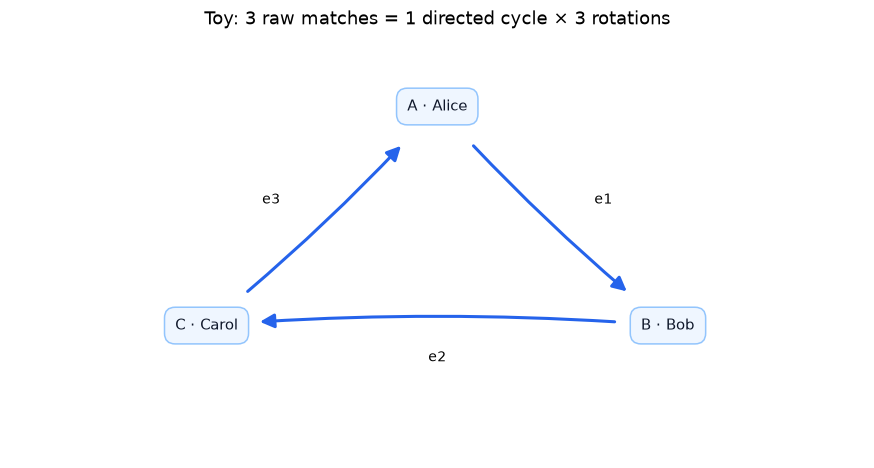

In [6]:
toy = build_toy_graph(spark)
display(toy.vertices.orderBy('id').toPandas())
display(toy.edges.orderBy('src').toPandas())
toy_result = run_demo(spark)
display(pd.DataFrame(toy_result['raw_matches'],columns=['a','b','c']))
assert (toy_result['raw_match_count'],toy_result['unique_cycle_count']) == (3,1)
draw_graph({'A':'A · Alice','B':'B · Bob','C':'C · Carol'},
    [('A','B','e1'),('B','C','e2'),('C','A','e3')],'Toy: 3 raw matches = 1 directed cycle × 3 rotations')
checks_passed['Toy graph.find: 3 rotations / 1 cycle'] = True


## 2 · Định nghĩa motif PaySim: cycle và relay

**Rule:** A −TRANSFER→ B −CASH_OUT→ C, ba tài khoản khác nhau, **cả hai amount >10.000**, `transfer_step <= cashout_step`, khoảng cách tối đa 24 giờ mô phỏng. Không dùng nhãn fraud để chọn ứng viên.

PaySim chỉ ghi giờ; cặp cùng giờ không xác định thứ tự thật. `strict_time=True` loại các cặp này. 24 giờ là tham số phân tích do nhóm chọn. Relay là **cặp giao dịch ứng viên**, chưa chứng minh cùng một khoản tiền đi qua hai hop.


In [7]:
RELAY_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c)"


In [8]:
# Code production đầy đủ: lọc cạnh, query, amount/time và flatten.
# Production: src/paysim/motif_finding.py

def find_relays(
    graph: GraphFrame, minimum_amount: float, max_gap_hours: int,
    strict_time: bool = False,
) -> DataFrame:
    """Find three-account relays; same-hour order is unknown in PaySim."""
    if not math.isfinite(minimum_amount) or minimum_amount < 0 or max_gap_hours <= 0:
        raise ValueError("finite minimum_amount >= 0 and max_gap_hours > 0 required")
    eligible_edges = graph.edges.where(
        F.col("type").isin("TRANSFER", "CASH_OUT")
        & (F.col("amount") > minimum_amount)
    )
    eligible_graph = GraphFrame(graph.vertices, eligible_edges)
    time_order = (F.col("e1.step") < F.col("e2.step")) if strict_time else (
        F.col("e1.step") <= F.col("e2.step")
    )
    return eligible_graph.find(RELAY_PATTERN).where(
        (F.col("e1.type") == "TRANSFER")
        & (F.col("e2.type") == "CASH_OUT")
        & (F.col("a.id") != F.col("b.id"))
        & (F.col("b.id") != F.col("c.id"))
        & (F.col("a.id") != F.col("c.id"))
        & time_order
        & ((F.col("e2.step") - F.col("e1.step")) <= max_gap_hours)
    )

def relay_rows(matches: DataFrame) -> DataFrame:
    """Flat columns for a CSV of transaction-pair candidates."""
    return matches.select(
        F.col("a.id").alias("source_account"),
        F.col("b.id").alias("middle_account"),
        F.col("c.id").alias("cashout_account"),
        F.col("e1.step").alias("transfer_step"),
        F.col("e2.step").alias("cashout_step"),
        F.col("e1.amount").alias("transfer_amount"),
        F.col("e2.amount").alias("cashout_amount"),
        F.col("e1.isFraud").alias("transfer_isFraud"),
        F.col("e2.isFraud").alias("cashout_isFraud"),
    )


### Kiểm tra rule trước khi chạy full

Các trường hợp cần phân biệt: số tiền **đúng 10.000** bị loại; thời gian ngược bị loại; cặp cùng giờ được giữ ở chế độ mặc định nhưng bị loại khi `strict_time=True`; khoảng cách **đúng 24 giờ** được giữ; ba tài khoản phải khác nhau. Nhãn fraud không quyết định việc relay có được chọn hay không.

Đồ thị hai tài khoản bên dưới còn kiểm chứng self-loop và cycle hai đỉnh không bị nhận nhầm thành cycle ba đỉnh.


In [9]:
# Cùng cấu trúc biên dùng trong test motif của repo; chỉ dùng rule PaySim.
vertices = spark.sql("SELECT * FROM VALUES ('A'),('B'),('D'),('E'),('F'),('X') AS v(id)")
edges = spark.sql(
    "SELECT * FROM VALUES "
    "('A','B','TRANSFER',10000.0,10,0),('X','B','TRANSFER',11000.0,10,1),"
    "('B','A','CASH_OUT',10000.0,12,0),('B','D','CASH_OUT',11000.0,10,0),"
    "('B','E','CASH_OUT',11000.0,34,0),('B','F','CASH_OUT',11000.0,35,0),"
    "('B','A','CASH_OUT',11000.0,9,0),('B','X','CASH_OUT',11000.0,12,0) "
    "AS e(src,dst,type,amount,step,isFraud)"
)
boundary_graph = GraphFrame(vertices, edges)
default_matches = find_relays(boundary_graph, 10_000, 24)
assert sorted(row.id for row in default_matches.select('c.id').collect()) == ['D', 'E']
assert find_relays(boundary_graph, 10_000, 24, strict_time=True).count() == 1

two_vertices = spark.sql("SELECT * FROM VALUES ('A'),('B') AS v(id)")
two_edges = spark.sql("SELECT * FROM VALUES ('A','B'),('B','A'),('A','A') AS e(src,dst)")
assert find_three_node_cycles(GraphFrame(two_vertices, two_edges)).count() == 0
for invalid in (float('nan'), float('inf'), -1.0):
    try:
        find_relays(boundary_graph, invalid, 24)
    except ValueError:
        continue
    raise AssertionError(f'Invalid threshold accepted: {invalid}')
print('PASS: amount, time order, 24-hour boundary, distinct accounts and invalid thresholds.')
checks_passed['PaySim: adversarial relay rules and three-node cycle definition'] = True


PASS: amount, time order, 24-hour boundary, distinct accounts and invalid thresholds.


## 3 · Chạy motif trên full PaySim

Không kết luận cycle full bằng 0 chỉ từ sample. Cell này tìm trên **9.073.900 đỉnh / 6.362.620 cạnh**, sau đó so từng dòng relay với CSV đã commit.


In [10]:
pay_loaded = load_graph(spark,str(REPO_ROOT/'data/processed/paysim'))
pay = GraphFrame(pay_loaded.vertices.select('id').cache(),pay_loaded.edges.select(
    'src','dst','type','amount','step','isFraud').cache())
pay_v,pay_e = pay.vertices.count(),pay.edges.count()
assert (pay_v,pay_e) == (9_073_900,6_362_620)
pay_cycles = find_three_node_cycles(pay)
pay_cycle_count = pay_cycles.count()
pay_directed_count = pay_cycles.where((F.col('a.id')<F.col('b.id')) &
    (F.col('a.id')<F.col('c.id'))).select('a.id','b.id','c.id').distinct().count()
pay_matches = find_relays(pay,10_000.0,24).cache()
pay_relay_count = pay_matches.count()
pay_same_hour = pay_matches.where(F.col('e1.step')==F.col('e2.step')).count()
pay_relays = relay_rows(pay_matches).orderBy('transfer_step','cashout_step','source_account',
    'middle_account','cashout_account','transfer_amount','cashout_amount').toPandas()
pay_metrics = {'scope':'full','vertices':pay_v,'edges':pay_e,'raw_cycles':pay_cycle_count,
    'directed_cycles':pay_directed_count,'relay_pairs':pay_relay_count,'same_hour':pay_same_hour,
    'strict_later':pay_relay_count-pay_same_hour}
assert (pay_cycle_count,pay_directed_count,pay_relay_count,pay_same_hour) == (0,0,30,2)
baseline = pd.read_csv(REPO_ROOT/'results/paysim/relay_candidates.csv')
keys = list(pay_relays.columns)
pd.testing.assert_frame_equal(pay_relays.sort_values(keys).reset_index(drop=True),
    baseline[keys].sort_values(keys).reset_index(drop=True),check_dtype=False,check_exact=True)
display(pd.DataFrame([pay_metrics]))
display(pay_relays.head(10))
assert (pay_relays[['transfer_isFraud','cashout_isFraud']]==0).all().all()
print('PASS: CSV khớp đủ 30/30; hai cạnh của mọi ứng viên đều có nhãn 0.')
checks_passed['Task 3 PaySim full + exact delivered CSV'] = True


,scope,vertices,edges,raw_cycles,directed_cycles,relay_pairs,same_hour,strict_later
0,full,9073900,6362620,0,0,30,2,28


,source_account,middle_account,cashout_account,transfer_step,cashout_step,transfer_amount,cashout_amount,transfer_isFraud,cashout_isFraud
0,C1933517957,C1939958280,C232785081,24,37,265406.49,400729.53,0,0
1,C831358900,C874023329,C1468339976,34,47,1326914.02,292696.43,0,0
2,C1554009922,C874023329,C1468339976,36,47,149467.61,292696.43,0,0
3,C1739712760,C1360393616,C654237876,44,44,161654.47,75989.57,0,0
4,C1483406592,C2013691076,C1228316980,129,132,255345.27,433722.00,0,0
5,C11465170,C1883483535,C792212230,139,139,456477.88,247241.29,0,0
6,C1076477679,C991247178,C1344561835,143,162,195823.90,60387.69,0,0
7,C532453433,C1708070258,C11164223,155,177,1310843.36,406454.19,0,0
8,C1558625741,C1838628808,C224572740,156,158,213684.91,123530.04,0,0
9,C1766969454,C1708070258,C11164223,156,177,822049.92,406454.19,0,0


PASS: CSV khớp đủ 30/30; hai cạnh của mọi ứng viên đều có nhãn 0.


## 4 · Đọc kết quả PaySim qua đồ thị

Hình thứ nhất chọn một relay có giờ CASH_OUT lớn hơn giờ TRANSFER. Mũi tên ghi loại giao dịch, số tiền và giờ mô phỏng. Hai số tiền không cần bằng nhau; dữ liệu chưa chứng minh đây là cùng một khoản tiền.

Hình thứ hai tách 28 cặp có thứ tự giờ rõ với 2 cặp cùng giờ. Cả 30 ứng viên có nhãn đối chiếu bằng 0, nên không được báo cáo thành “30 vụ gian lận”.


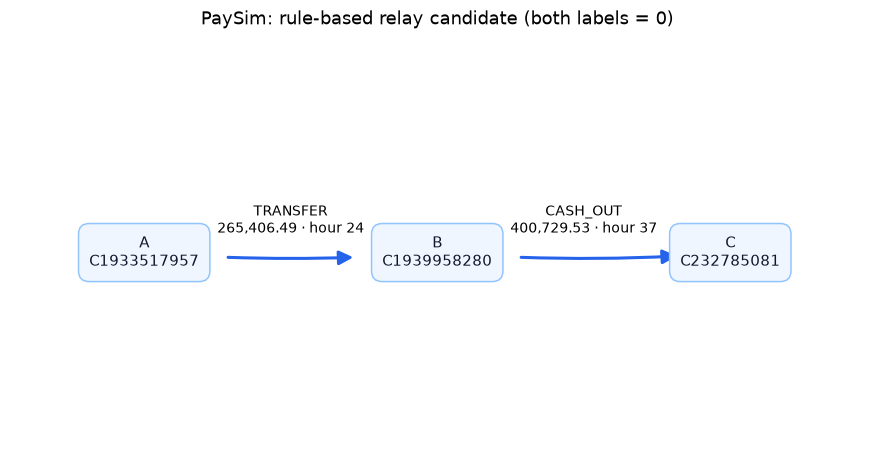

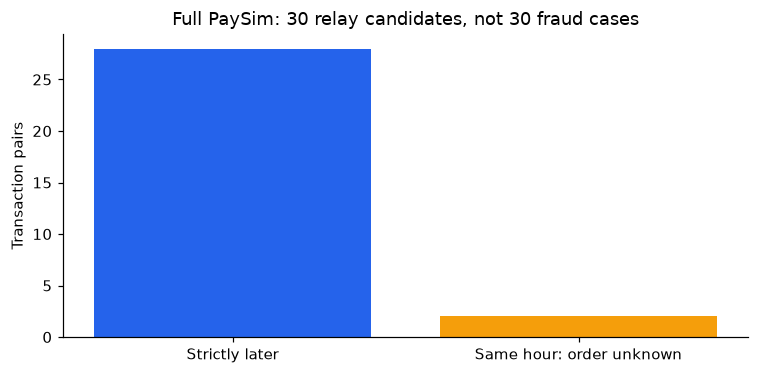

In [11]:
# Chọn ứng viên có thứ tự giờ rõ ràng. Hai amount không cần bằng nhau.
example = pay_relays.loc[pay_relays.cashout_step>pay_relays.transfer_step].iloc[0]
draw_graph({'A':'A\n'+example.source_account,'B':'B\n'+example.middle_account,
            'C':'C\n'+example.cashout_account},
    [('A','B',f'TRANSFER\n{example.transfer_amount:,.2f} · hour {example.transfer_step}'),
     ('B','C',f'CASH_OUT\n{example.cashout_amount:,.2f} · hour {example.cashout_step}')],
    'PaySim: rule-based relay candidate (both labels = 0)',
    positions={'A':(-1.1,0),'B':(0,0),'C':(1.1,0)})
fig,ax = plt.subplots(figsize=(7,3.5))
ax.bar(['Strictly later','Same hour: order unknown'],[pay_relay_count-pay_same_hour,pay_same_hour],
       color=['#2563eb','#f59e0b'])
ax.set(ylabel='Transaction pairs',title='Full PaySim: 30 relay candidates, not 30 fraud cases')
plt.tight_layout()
plt.show()
pay_matches.unpersist()
pay.vertices.unpersist()
pay.edges.unpersist()
spark.catalog.clearCache()


### Kết luận thực nghiệm PaySim

- Query cycle **ba đỉnh** trên full graph cho **0 kết quả**; điều này không tự chứng minh graph không có mọi loại cycle khác.
- Rule TRANSFER → CASH_OUT cho **30 cặp giao dịch**, gồm **28** cặp khác giờ và **2** cặp cùng giờ.
- Toàn bộ relay khớp từng dòng với CSV bàn giao, không chỉ khớp số lượng.
- Không dùng fraud label để lọc ứng viên; nhãn chỉ phục vụ đối chiếu sau query.
- Cửa sổ 24 giờ là tham số phân tích; relay không chứng minh cùng một khoản tiền đi qua hai hop.


## 5 · Điều tra nguyên nhân và hiệu chỉnh motif PaySim

**H1 — chỉ cần đổi amount/time của relay là sẽ tìm được fraud:** kiểm tra trên toàn bộ relay không giới hạn ngưỡng trước khi kết luận. Cycle ba đỉnh bằng 0 là kết quả cấu trúc; lọc cạnh không thể tạo ra vòng không tồn tại.

**H2 — một nơi nhận CASH_OUT từ nhiều nguồn có thể mang thông tin rủi ro:** dùng fan-in `A → B ← C`. Cạnh `C → B` là giao dịch đang đánh giá, `A → B` phải từ **người gửi khác, xảy ra ở giờ trước**. Không suy diễn đây là cùng một khoản tiền hay cả hai người gửi đều fraud.

Chỉ dùng quan hệ tài khoản, loại giao dịch, amount và giờ mô phỏng. Không dùng balance sau giao dịch hoặc `isFlaggedFraud`. Đây là motif khác relay/cycle, được bổ sung riêng để kiểm định H2; không đổi tên fan-in thành vòng tiền.

Grid cố định: cửa sổ **1, 6, 24, 72 giờ** × số giao dịch trước đó tối thiểu **1, 2, 5** × ngưỡng amount **0 / q90 / q95 / q99 / q99.5 / q99.9** trên training CASH_OUT. Tổng **72 rule motif**, thêm **6 rule amount-only** để xem phần cấu trúc có thực sự giúp hay không. Volume không phải số lượng người gửi khác nhau; luôn cần ít nhất một witness khác nguồn.

Nguồn dataset: [PaySim của tác giả](https://github.com/EdgarLopezPhD/PaySim) và [bản CSV được phân phối](https://www.kaggle.com/datasets/ealaxi/paysim1). Các kết luận số liệu bên dưới được tính từ Parquet local, không lấy từ bài viết trên mạng.


### Quy trình đánh giá và tiêu chí chọn ngưỡng (khóa trước khi chạy)

1. Gắn ID **cho từng dòng giao dịch**, giữ cả các dòng trùng nội dung. ID chỉ có ý nghĩa trong lần chạy này.
2. Chia khoảng **60% / 20% / 20% theo thời gian**, giữ mọi giao dịch cùng timestamp trong cùng tập. In ranh giới và số lượng thực tế, không giả định các tập có cùng tỷ lệ fraud.
3. Học ngưỡng phân vị tiền từ **training không có nhãn**; chọn rule bằng **F1 trên validation**, sau đó precision, ít FP hơn, và ID rule để phá hòa. Không tối ưu accuracy vì dữ liệu mất cân bằng.
4. Khóa rule rồi mới đánh giá test. TP/FP/FN/TN tính theo **giao dịch ra quyết định duy nhất**, không tính theo số tổ hợp motif. Mẫu số gồm **mọi giao dịch**, kể cả loại mà rule không hỗ trợ.
5. Nhãn chỉ đi vào audit và scorer; feature builder từ chối nhận `isFraud`/`isLaundering`. Không có TP trên validation thì **abstain**, không tự nới ngưỡng để ép ra fraud.

`isFraud` là ground truth. `alert=1` là đề nghị kiểm tra; `alert=0` không chứng minh giao dịch hợp pháp. Precision không xác định khi không có alert; recall không xác định khi không có fraud. Ngưỡng được gọi là **tốt nhất trong grid theo validation**, không phải tối ưu toàn cục.

Đây là **internal temporal holdout** của dataset đã được khám phá trong project, không phải benchmark ngoài mẫu hoàn toàn mới. Một lần chia thời gian chưa đo được độ ổn định hay khả năng áp dụng vào ngân hàng thật. Khung thời gian tham khảo cách đánh giá của [nhóm tác giả IBM AMLworld](https://arxiv.org/html/2306.16424v3#S4); mô hình ở đây là rule motif, không sao chép kết quả của họ.


In [12]:
# Production: src/motif/evaluation.py — đầy đủ code đang được thực thi

def require_unlabelled(frame: DataFrame) -> None:
    """Fail closed if a feature/query path accidentally receives ground truth."""
    forbidden = {"isfraud", "islaundering", "isflaggedfraud", "label", "target"}
    leaked = forbidden.intersection(name.lower() for name in frame.columns)
    if leaked:
        raise ValueError(f"Ground truth in feature builder: {sorted(leaked)}")


def index_transactions(edges: DataFrame) -> DataFrame:
    """Assign one run-local ID per physical row, including identical records.

    Materializing once freezes IDs before self-joins. These are not persistent
    transaction IDs and must not be compared across independent Spark runs.
    """
    if "event_id" in edges.columns:
        raise ValueError("event_id already exists")
    return edges.withColumn("event_id", F.monotonically_increasing_id()).localCheckpoint(eager=True)


def temporal_cutoffs(features: DataFrame) -> tuple[int, int]:
    """Approximately 60/20/20 by row count; keep timestamp ties in one split."""
    require_unlabelled(features)
    cuts = features.approxQuantile("step", [0.6, 0.8], 0.001)
    if len(cuts) != 2 or cuts[0] >= cuts[1]:
        raise ValueError("Need two distinct timestamp boundaries")
    return int(cuts[0]), int(cuts[1])


def split_expression(cutoffs: tuple[int, int]):
    """The same predicate is used for features and ground-truth denominators."""
    first, second = cutoffs
    if first >= second:
        raise ValueError("Temporal boundaries must increase")
    return F.when(F.col("step") <= first, "train").when(
        F.col("step") <= second, "validation"
    ).otherwise("test")


In [13]:
# Production: src/motif/evaluation.py — đầy đủ code đang được thực thi

def binary_metrics(total: int, positives: int, tp: int, fp: int) -> dict:
    """No accuracy shortcut; undefined precision/recall remain explicitly None."""
    values = (total, positives, tp, fp)
    if any(not math.isfinite(v) or int(v) != v or v < 0 for v in values):
        raise ValueError("Confusion counts must be finite nonnegative integers")
    if positives > total or tp > positives or fp > total - positives:
        raise ValueError("Inconsistent confusion matrix")
    fn, tn = int(positives - tp), int(total - positives - fp)
    alerts = int(tp + fp)
    return {
        "transactions": int(total), "fraud": int(positives),
        "alerts": alerts, "TP": int(tp), "FP": int(fp), "FN": fn, "TN": tn,
        "precision": tp / alerts if alerts else None,
        "recall": tp / positives if positives else None,
        "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else None,
        "prevalence": positives / total if total else None,
        "alert_rate": alerts / total if total else None,
    }


def evaluate_alerts(alerts: DataFrame, truth: DataFrame) -> pd.DataFrame:
    """One prediction per transaction, never one per motif combination.

    truth has event_id, split, isFraud. Denominators include *all* transactions,
    including types/currencies that a particular motif cannot reach.
    """
    ids = alerts.select("event_id").distinct().withColumn("alert", F.lit(1))
    counts = truth.join(ids, "event_id", "left").groupBy("split").agg(
        F.count("*").alias("total"), F.sum("isFraud").alias("positives"),
        F.sum(F.when((F.col("alert") == 1) & (F.col("isFraud") == 1), 1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col("alert") == 1) & (F.col("isFraud") == 0), 1).otherwise(0)).alias("fp"),
    ).collect()
    records = [{"split": row.split, **binary_metrics(row.total, row.positives, row.tp, row.fp)}
               for row in counts]
    return pd.DataFrame(records).set_index("split").reindex(["train", "validation", "test"]).reset_index()


def select_validation_rule(scores: pd.DataFrame) -> dict:
    """Maximize validation F1, then precision, fewer FP, stable rule ID.

    The caller passes only validation scores. No supported true positive means
    abstain, rather than selecting an arbitrary rule merely to emit alerts.
    """
    if scores.empty or not (scores["TP"] > 0).any():
        return {"rule_id": "abstain", "reason": "No validation true positive; no supported threshold"}
    ranked = scores.assign(
        _f1=scores["F1"].fillna(-1), _precision=scores["precision"].fillna(-1)
    ).sort_values(["_f1", "_precision", "FP", "rule_id"], ascending=[False, False, True, True])
    return ranked.iloc[0].drop(labels=["_f1", "_precision"]).to_dict()


In [14]:
# Audit chẩn đoán: nhãn chỉ được xem sau khi đã tạo tất cả cặp theo cấu trúc.
pay_all = pay_loaded.edges
pay_types = pay_all.groupBy('type','isFraud').count().orderBy('type','isFraud').toPandas()
display(pay_types)
t = pay_all.where("type='TRANSFER'").alias('t')
c = pay_all.where("type='CASH_OUT'").alias('c')
relay_audit = t.join(c,F.col('t.dst')==F.col('c.src')).where('t.src != c.dst').selectExpr(
    't.src source','t.dst middle','c.dst destination','t.amount transfer_amount',
    'c.amount cashout_amount','t.step transfer_step','c.step cashout_step',
    'c.step-t.step gap_hours','t.isFraud transfer_isFraud','c.isFraud cashout_isFraud')
display(relay_audit.groupBy('transfer_isFraud','cashout_isFraud').count().toPandas())
display(relay_audit.where('transfer_isFraud=1 OR cashout_isFraud=1').orderBy('gap_hours').toPandas())
display(relay_audit.where('gap_hours > 0 AND gap_hours <= 72').groupBy(
    'transfer_isFraud','cashout_isFraud').count().toPandas())
print('H1: chỉ 3 cặp có một cạnh fraud; hai cặp ngược thời gian, một cặp cách 481 giờ.')
print('Không có CASH_OUT mang nhãn fraud trong bất kỳ relay nào, ngay cả trước lọc thời gian.')


,type,isFraud,count
0,CASH_IN,0,1399284
1,CASH_OUT,0,2233384
2,CASH_OUT,1,4116
3,DEBIT,0,41432
4,PAYMENT,0,2151495
5,TRANSFER,0,528812
6,TRANSFER,1,4097


,transfer_isFraud,cashout_isFraud,count
0,0,0,569
1,1,0,3


,source,middle,destination,transfer_amount,cashout_amount,transfer_step,cashout_step,gap_hours,transfer_isFraud,cashout_isFraud
0,C2029041842,C1023330867,C1422447255,814689.88,29084.28,738,132,-606,1,0
1,C2140495649,C423543548,C1066927674,214793.32,214555.85,486,185,-301,1,0
2,C1175896731,C1714931087,C1339132632,1282971.57,18091.05,65,546,481,1,0


,transfer_isFraud,cashout_isFraud,count
0,0,0,74


H1: chỉ 3 cặp có một cạnh fraud; hai cặp ngược thời gian, một cặp cách 481 giờ.
Không có CASH_OUT mang nhãn fraud trong bất kỳ relay nào, ngay cả trước lọc thời gian.


In [15]:
# Production: src/paysim/motif_finding.py — đầy đủ code đang được thực thi

def build_fanin_features(
    features: DataFrame, windows: tuple[int, ...] = (1, 6, 24, 72),
) -> DataFrame:
    """Causal CASH_OUT fan-in A -> B <- C with two different senders.

    Each current transaction is the decision event. Only earlier *hours* may
    supply a witness; within-hour order is unknown. A range window computes
    motif existence without enumerating the quadratic number of edge pairs.
    prior_count is transaction volume, not a count of distinct people.
    """
    from pyspark.sql.window import Window

    require_unlabelled(features)
    if not windows or any(isinstance(h, bool) or not isinstance(h, int) or h <= 0 for h in windows):
        raise ValueError("windows must contain positive integer hours")
    result = features.where((F.col("type") == "CASH_OUT") & (F.col("src") != F.col("dst")))
    for hours in windows:
        history = Window.partitionBy("dst").orderBy("step").rangeBetween(-hours, -1)
        # min/max by source guarantees a different-source witness if one exists.
        record = F.struct("src", "step", "amount", "event_id")
        result = result.withColumn("_first", F.min(record).over(history)).withColumn(
            "_last", F.max(record).over(history)
        ).withColumn(f"prior_count_{hours}", F.count("*").over(history))
        witness = F.when(F.col("_first.src") != F.col("src"), F.col("_first")).when(
            F.col("_last.src") != F.col("src"), F.col("_last")
        )
        result = result.withColumn(f"witness_{hours}", witness).drop("_first", "_last")
    return result


def fanin_training_thresholds(features: DataFrame, train_end: int) -> list[dict]:
    """Amount scale is learned only from unlabelled training CASH_OUT rows."""
    require_unlabelled(features)
    quantiles = [0.9, 0.95, 0.99, 0.995, 0.999]
    amounts = features.where(
        (F.col("step") <= train_end) & (F.col("type") == "CASH_OUT") & (F.col("amount") > 0)
    ).approxQuantile("amount", quantiles, 0.0001)
    if len(amounts) != len(quantiles):
        raise ValueError("No training CASH_OUT amount distribution")
    return [{"quantile": q, "minimum_amount": float(a)}
            for q, a in zip([0.0, *quantiles], [0.0, *amounts])]


In [16]:
# Production: src/paysim/motif_finding.py — đầy đủ code đang được thực thi

def fanin_alerts(fan: DataFrame, rule: dict) -> DataFrame:
    """Label-blind decision predicate, also used after freezing the rule."""
    require_unlabelled(fan)
    if rule["rule_id"] == "abstain":
        return fan.where(F.lit(False))
    predicate = F.col("amount") > float(rule["minimum_amount"])
    if rule["family"] == "fanin":
        hours = int(rule["window_hours"])
        predicate = predicate & F.col(f"witness_{hours}").isNotNull() & (
            F.col(f"prior_count_{hours}") >= int(rule["minimum_priors"])
        )
    return fan.where(predicate)


def score_fanin_validation(
    fan: DataFrame, truth: DataFrame, thresholds: list[dict],
    windows: tuple[int, ...] = (1, 6, 24, 72),
    minimum_priors: tuple[int, ...] = (1, 2, 5),
):
    """Score a fixed grid from a small histogram of validation rows only.

    Returns separate motif and amount-only families for a structural ablation.
    Test labels are never joined or returned by this function.
    """
    import pandas as pd

    require_unlabelled(fan)
    validation = truth.where(F.col("split") == "validation")
    support = validation.agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
    if not support.n:
        raise ValueError("Empty validation split")
    labelled = fan.where(F.col("split") == "validation").join(
        validation.select("event_id", "isFraud"), "event_id"
    )
    band = sum((F.when(F.col("amount") > t["minimum_amount"], 1).otherwise(0)
                for t in thresholds), F.lit(0))
    buckets = [F.struct(
        F.lit(h).alias("hours"),
        F.least(F.col(f"prior_count_{h}"), F.lit(max(minimum_priors))).alias("prior_count"),
        F.col(f"witness_{h}").isNotNull().alias("other_source"),
    ) for h in windows]
    histogram = labelled.select(
        "isFraud", band.alias("band"), F.explode(F.array(*buckets)).alias("bucket")
    ).select("isFraud", "band", "bucket.*").groupBy(
        "band", "hours", "prior_count", "other_source"
    ).agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).toPandas()
    records = []
    for rank, threshold in enumerate(thresholds):
        amount_mask = histogram["band"] >= rank + 1
        for hours in windows:
            for count in minimum_priors:
                mask = amount_mask & (histogram.hours == hours) & histogram.other_source & (
                    histogram.prior_count >= count
                )
                n, p = histogram.loc[mask, ["n", "p"]].sum()
                records.append({
                    "rule_id": f"fanin_h{hours:03d}_n{count}_q{rank}", "family": "fanin",
                    "window_hours": hours, "minimum_priors": count, **threshold,
                    **binary_metrics(support.n, support.p, int(p), int(n - p)),
                })
        # Each current row appears once per window; choose one window for baseline.
        n, p = histogram.loc[amount_mask & (histogram.hours == windows[0]), ["n", "p"]].sum()
        records.append({
            "rule_id": f"amount_q{rank}", "family": "amount_only",
            "window_hours": 0, "minimum_priors": 0, **threshold,
            **binary_metrics(support.n, support.p, int(p), int(n - p)),
        })
    return pd.DataFrame(records)


In [17]:
# Tách feature và nhãn ngay tại đầu pipeline. Các phép window không nhận nhãn.
pay_indexed = index_transactions(pay_loaded.edges)
pay_features = pay_indexed.drop('isFraud')
pay_cutoffs = temporal_cutoffs(pay_features)
pay_features = pay_features.withColumn('split',split_expression(pay_cutoffs))
pay_truth = pay_indexed.withColumn('split',split_expression(pay_cutoffs)).select('event_id','split','isFraud')
display(pd.DataFrame([{'train_end_hour':pay_cutoffs[0],'validation_end_hour':pay_cutoffs[1]}]))
display(pay_truth.groupBy('split').agg(F.count('*').alias('transactions'),F.sum('isFraud').alias('fraud')).toPandas())
pay_thresholds = fanin_training_thresholds(pay_features,pay_cutoffs[0])
display(pd.DataFrame(pay_thresholds))
# Window SQL tương đương kiểm tra tồn tại motif fan-in, tránh sinh O(degree^2) cặp.
pay_fan = build_fanin_features(pay_features).localCheckpoint(eager=True)
for hours in (1,6,24,72):
    assert pay_fan.where(F.col(f'witness_{hours}').isNotNull() & (
        (F.col(f'witness_{hours}.src')==F.col('src')) |
        (F.col(f'witness_{hours}.step')>=F.col('step')) |
        (F.col('step')-F.col(f'witness_{hours}.step')>hours))).count()==0
pay_validation_scores = score_fanin_validation(pay_fan,pay_truth,pay_thresholds)
pay_rule = select_validation_rule(pay_validation_scores.query("family=='fanin'"))
pay_amount_rule = select_validation_rule(pay_validation_scores.query("family=='amount_only'"))
display(pay_validation_scores.sort_values(['F1','precision'],ascending=False).head(12))
display(pd.DataFrame([{'model':'motif fan-in',**pay_rule},{'model':'amount-only',**pay_amount_rule}]))
print('Đã khóa hai cấu hình theo validation. Không sửa grid sau khi nhìn kết quả test.')


,train_end_hour,validation_end_hour
0,281,355


,split,transactions,fraud
0,validation,1293285,770
1,test,1248736,4250
2,train,3820599,3193


,quantile,minimum_amount
0,0.000,0.00
1,0.900,357893.81
2,0.950,431317.52
3,0.990,585039.45
4,0.995,649146.55
5,0.999,838316.69


,rule_id,family,window_hours,minimum_priors,quantile,minimum_amount,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence,alert_rate
77,amount_q5,amount_only,0,0,0.999,838316.69,1293285,770,209,128,81,642,1292434,0.612440,0.166234,0.261491,0.000595,0.000162
74,fanin_h072_n1_q5,fanin,72,1,0.999,838316.69,1293285,770,117,69,48,701,1292467,0.589744,0.089610,0.155581,0.000595,0.000090
64,amount_q4,amount_only,0,0,0.995,649146.55,1293285,770,1723,152,1571,618,1290944,0.088218,0.197403,0.121941,0.000595,0.001332
75,fanin_h072_n2_q5,fanin,72,2,0.999,838316.69,1293285,770,61,37,24,733,1292491,0.606557,0.048052,0.089049,0.000595,0.000047
61,fanin_h072_n1_q4,fanin,72,1,0.995,649146.55,1293285,770,1051,81,970,689,1291545,0.077069,0.105195,0.088962,0.000595,0.000813
51,amount_q3,amount_only,0,0,0.990,585039.45,1293285,770,3911,165,3746,605,1288769,0.042189,0.214286,0.070498,0.000595,0.003024
71,fanin_h024_n1_q5,fanin,24,1,0.999,838316.69,1293285,770,61,29,32,741,1292483,0.475410,0.037662,0.069795,0.000595,0.000047
62,fanin_h072_n2_q4,fanin,72,2,0.995,649146.55,1293285,770,585,43,542,727,1291973,0.073504,0.055844,0.063469,0.000595,0.000452
58,fanin_h024_n1_q4,fanin,24,1,0.995,649146.55,1293285,770,502,36,466,734,1292049,0.071713,0.046753,0.056604,0.000595,0.000388
48,fanin_h072_n1_q3,fanin,72,1,0.990,585039.45,1293285,770,2365,86,2279,684,1290236,0.036364,0.111688,0.054864,0.000595,0.001829


,model,rule_id,family,window_hours,minimum_priors,quantile,minimum_amount,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence,alert_rate
0,motif fan-in,fanin_h072_n1_q5,fanin,72,1,0.999,838316.69,1293285,770,117,69,48,701,1292467,0.589744,0.089610,0.155581,0.000595,0.000090
1,amount-only,amount_q5,amount_only,0,0,0.999,838316.69,1293285,770,209,128,81,642,1292434,0.612440,0.166234,0.261491,0.000595,0.000162


Đã khóa hai cấu hình theo validation. Không sửa grid sau khi nhìn kết quả test.


### Đánh giá cấu hình đã khóa và kiểm tra giả thuyết

Bảng dưới dùng toàn bộ giao dịch làm mẫu số. Fan-in hiện chỉ có thể cảnh báo CASH_OUT; nó không thể bao phủ fraud thuộc TRANSFER. So sánh với amount-only là ablation: nếu thêm motif làm F1 giảm thì H2 chưa được chứng minh có lợi, dù có TP khác 0.

Cửa sổ luôn nhìn về quá khứ. Mọi giao dịch cùng giờ hiện tại bị loại khỏi witness vì PaySim không cung cấp thứ tự bên trong giờ. Nhãn witness không ảnh hưởng quyết định; nó được hiển thị sau đó để người đọc không nhầm hai cạnh đều là fraud.


In [18]:
pay_selected = fanin_alerts(pay_fan,pay_rule).localCheckpoint(eager=True)
pay_amount_selected = fanin_alerts(pay_fan,pay_amount_rule)
pay_evaluations = pd.concat([
    evaluate_alerts(pay_selected,pay_truth).assign(model='fan-in motif'),
    evaluate_alerts(pay_amount_selected,pay_truth).assign(model='amount-only'),
    evaluate_alerts(pay_features.where(F.lit(False)),pay_truth).assign(model='no-alert baseline'),
],ignore_index=True)
display(pay_evaluations[['model','split','transactions','fraud','alerts','TP','FP','FN','TN','precision','recall','F1','prevalence']])
# Kiểm chứng scorer validation dùng đúng predicate được deploy.
pay_validation_check = pay_evaluations.query("model=='fan-in motif' and split=='validation'").iloc[0]
if pay_rule['rule_id']!='abstain':
    assert (pay_validation_check.TP,pay_validation_check.FP)==(pay_rule['TP'],pay_rule['FP'])
# Các bảng nhỏ có cả phát hiện đúng, báo nhầm và bỏ sót, không cherry-pick chỉ fraud.
pay_alert_details = pay_selected.join(pay_truth.select('event_id','isFraud'),'event_id')
for title,label in [('TP: cảnh báo có nhãn fraud',1),('FP: cảnh báo nhưng nhãn normal',0)]:
    print(title)
    display(pay_alert_details.where((F.col('split')=='test') & (F.col('isFraud')==label)).orderBy('step').limit(3).toPandas())
print('FN: fraud test không được cảnh báo')
pay_missed = pay_features.join(pay_selected.select('event_id').distinct(),'event_id','left_anti').join(
    pay_truth.select('event_id','isFraud'),'event_id').where("split='test' AND isFraud=1")
display(pay_missed.orderBy('step').limit(3).toPandas())
checks_passed['PaySim: causal fan-in, validation selection and unique transaction confusion counts'] = True


,model,split,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence
0,fan-in motif,train,3820599,3193,931,310,621,2883,3816785,0.332975,0.097087,0.150339,0.000836
1,fan-in motif,validation,1293285,770,117,69,48,701,1292467,0.589744,0.089610,0.155581,0.000595
2,fan-in motif,test,1248736,4250,142,101,41,4149,1244445,0.711268,0.023765,0.045993,0.003403
3,amount-only,train,3820599,3193,1381,570,811,2623,3816595,0.412744,0.178516,0.249235,0.000836
4,amount-only,validation,1293285,770,209,128,81,642,1292434,0.61244,0.166234,0.261491,0.000595
5,amount-only,test,1248736,4250,878,798,80,3452,1244406,0.908884,0.187765,0.311232,0.003403
6,no-alert baseline,train,3820599,3193,0,0,0,3193,3817406,None,0.000000,0.000000,0.000836
7,no-alert baseline,validation,1293285,770,0,0,0,770,1292515,None,0.000000,0.000000,0.000595
8,no-alert baseline,test,1248736,4250,0,0,0,4250,1244486,None,0.000000,0.000000,0.003403


TP: cảnh báo có nhãn fraud


,event_id,src,dst,amount,step,type,split,prior_count_1,witness_1,prior_count_6,witness_6,prior_count_24,witness_24,prior_count_72,witness_72,isFraud
0,8591350875,C902008507,C1795644557,5952739.30,356,CASH_OUT,test,0,None,0,None,0,None,2,"(C1149691957, 285, 167896.95, 25771090470)",1
1,8591409987,C1918267923,C1297204700,2239461.29,357,CASH_OUT,test,0,None,1,"(C1090945757, 351, 65029.14, 8590545084)",1,"(C1090945757, 351, 65029.14, 8590545084)",2,"(C1090945757, 351, 65029.14, 8590545084)",1
2,8591394375,C498447652,C17820769,1438737.78,358,CASH_OUT,test,0,None,1,"(C515687392, 352, 392681.22, 1420100)",1,"(C515687392, 352, 392681.22, 1420100)",2,"(C10768316, 288, 288776.4, 8590439844)",1


FP: cảnh báo nhưng nhãn normal


,event_id,src,dst,amount,step,type,split,prior_count_1,witness_1,prior_count_6,witness_6,prior_count_24,witness_24,prior_count_72,witness_72,isFraud
0,17181318742,C2005590290,C1986965056,892356.38,370,CASH_OUT,test,0,None,0,None,0,None,1,"(C716794450, 308, 188984.2, 8591281086)",0
1,25770462576,C1324842844,C1971732851,870950.80,370,CASH_OUT,test,0,None,0,None,1,"(C394765405, 356, 102224.66, 17181310236)",1,"(C394765405, 356, 102224.66, 17181310236)",0
2,17181325333,C1863749514,C1196877536,2051867.52,370,CASH_OUT,test,0,None,0,None,1,"(C797151272, 355, 79190.97, 25770429137)",2,"(C1809987313, 299, 585677.02, 1315112)",0


FN: fraud test không được cảnh báo


,event_id,src,dst,amount,step,type,split,isFraud
0,614838,C1569009550,C1429463996,5952739.30,356,TRANSFER,test,1
1,17180487468,C850424960,C1620165471,7360.15,356,CASH_OUT,test,1
2,8591366072,C854622383,C1455552961,7360.15,356,TRANSFER,test,1


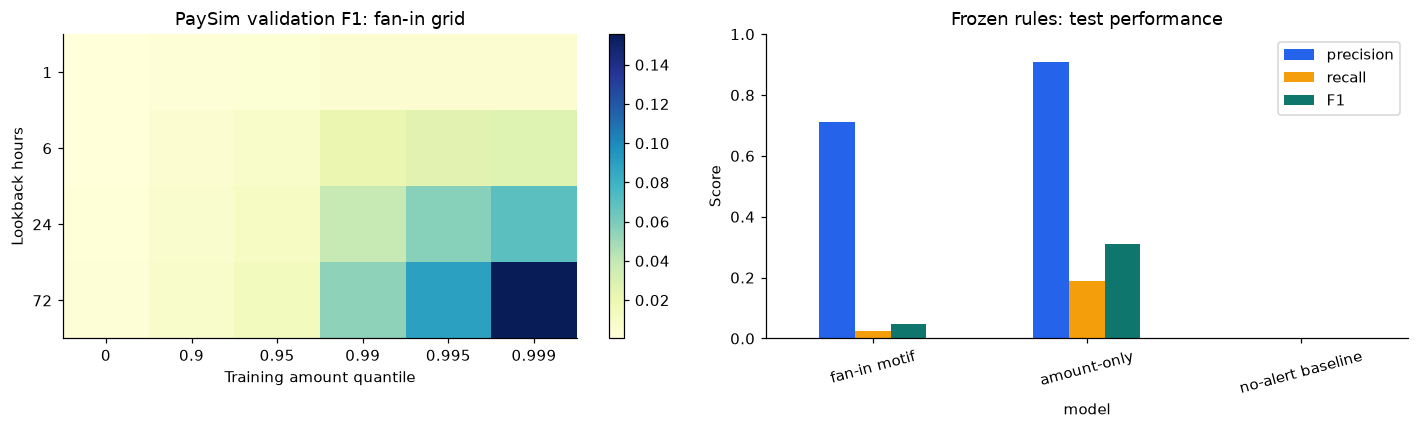

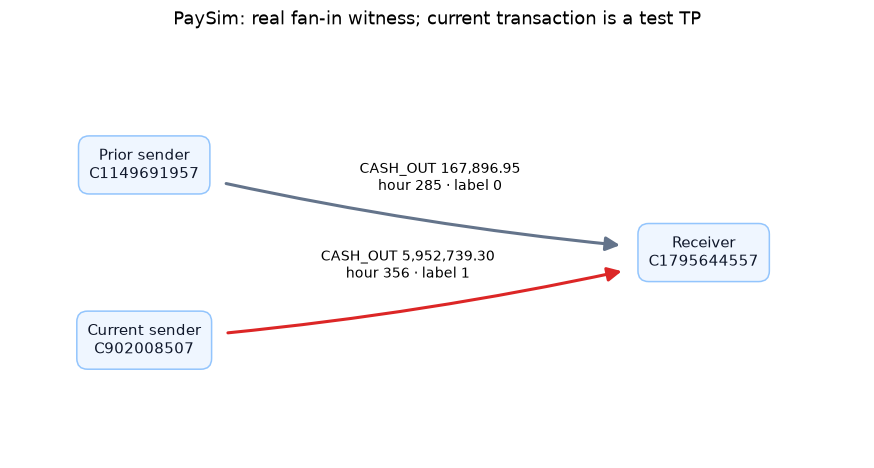

Fan-in test: TP=101, FP=41, FN=4149.
H2: fan-in có F1 test cao hơn amount-only: False
Kết quả cycle vẫn bằng 0. Fan-in là tín hiệu bổ sung, không phải vòng tiền đã tìm thấy.


In [19]:
# Đồ thị validation: mỗi ô là cấu hình tốt nhất theo volume tại giờ/ngưỡng đó.
heat = pay_validation_scores.query("family=='fanin'").pivot_table(index='window_hours',columns='quantile',values='F1',aggfunc='max')
fig,axes=plt.subplots(1,2,figsize=(13,4))
image=axes[0].imshow(heat.values,aspect='auto',cmap='YlGnBu')
axes[0].set(xticks=range(len(heat.columns)),xticklabels=[f'{q:g}' for q in heat.columns],
            yticks=range(len(heat.index)),yticklabels=heat.index,xlabel='Training amount quantile',
            ylabel='Lookback hours',title='PaySim validation F1: fan-in grid')
fig.colorbar(image,ax=axes[0])
comparison=pay_evaluations.query("split=='test'").set_index('model')
comparison[['precision','recall','F1']].plot.bar(ax=axes[1],rot=15,color=['#2563eb','#f59e0b','#0f766e'])
axes[1].set(title='Frozen rules: test performance',ylim=(0,1),ylabel='Score')
plt.tight_layout();plt.show()
# Ví dụ thật: ưu tiên TP trên test; nếu không có, giữ trạng thái không có TP.
if pay_rule['rule_id']!='abstain':
    hours=int(pay_rule['window_hours'])
    examples=pay_alert_details.where("split='test' AND isFraud=1").orderBy('step').limit(1).collect()
    if examples:
        row=examples[0]; witness=row[f'witness_{hours}']
        witness_label=pay_truth.where(F.col('event_id')==witness.event_id).first().isFraud
        draw_graph({'A':'Prior sender\n'+witness.src,'B':'Receiver\n'+row.dst,'C':'Current sender\n'+row.src},
            [('A','B',f'CASH_OUT {witness.amount:,.2f}\nhour {witness.step} · label {witness_label}'),
             ('C','B',f'CASH_OUT {row.amount:,.2f}\nhour {row.step} · label {row.isFraud}')],
            'PaySim: real fan-in witness; current transaction is a test TP',
            positions={'A':(-1.1,0.6),'B':(1,0),'C':(-1.1,-0.6)},colors=['#64748b','#dc2626'])
    else:
        print('Không có TP fan-in trên test; không tạo hình fraud giả.')
# Báo cáo kết luận từ số liệu vừa chạy, không hardcode một kết quả thuận lợi.
motif_test=comparison.loc['fan-in motif']; amount_test=comparison.loc['amount-only']
print(f"Fan-in test: TP={int(motif_test.TP)}, FP={int(motif_test.FP)}, FN={int(motif_test.FN)}.")
print('H2: fan-in có F1 test cao hơn amount-only:',bool(motif_test.F1>amount_test.F1))
print('Kết quả cycle vẫn bằng 0. Fan-in là tín hiệu bổ sung, không phải vòng tiền đã tìm thấy.')


### Kết luận từ lần chạy đã lưu

Validation chọn fan-in **72 giờ, ít nhất 1 giao dịch trước từ nguồn khác, current amount >838.316,69** (q99.9 training CASH_OUT). Trên test có **101 TP / 41 FP / 4.149 FN**, precision **71,13%**, recall **2,38%**, F1 **4,60%**. Đây là bằng chứng có khả năng chọn được fraud, đồng thời là bằng chứng recall thấp.

Amount-only với cùng ngưỡng, được chọn độc lập trên validation, có **798 TP / 80 FP / 3.452 FN**, precision **90,89%**, recall **18,78%**, F1 **31,12%** trên test. Nó đã tốt hơn fan-in ngay trên validation, và vẫn tốt hơn trên test. **H2 không được ủng hộ như một cải tiến detector:** không nên ép dùng fan-in làm mô hình tốt nhất chỉ để có motif. Giữ nó như feature ứng viên có bằng chứng, chưa khẳng định thêm vào PageRank/LPA sẽ giúp.

Mẫu số test là **1.248.736 giao dịch, 4.250 fraud**. Prevalence thay đổi giữa train/validation/test; số fraud nhiều hơn trên test không có nghĩa mô hình học tốt hơn. Không dùng test này để chọn lại ngưỡng. Cycle vẫn bằng 0 và không được “sửa” thành fan-in để báo tìm thấy vòng.

### Bàn giao để kết hợp PageRank/LPA

Feature motif giữ `event_id`, `src`, `dst`, `step`, amount, số giao dịch trước đó và witness. Có thể join PageRank của người gửi/người nhận hoặc cộng đồng theo ID tài khoản, **tính trên graph đã quan sát tại thời điểm quyết định**. `event_id` phải được giữ từ cùng lần index; không join ID giữa hai lần Spark độc lập.

Không đưa ground truth, tỷ lệ fraud community tính từ nhãn test, hoặc PageRank/LPA nhìn trước tương lai vào feature. Pipeline kết hợp cần chọn lại trên validation và đánh giá riêng; notebook này chưa tuyên bố hiệu quả của mô hình kết hợp. Không cộng nhầm số motif thành số giao dịch fraud.


In [20]:
# Giải phóng dữ liệu experiment trước phần review lý thuyết.
pay_selected.unpersist();pay_fan.unpersist();pay_indexed.unpersist()
spark.catalog.clearCache()


## 6 · Phụ lục: review và final PageRank 3.3

### Dẫn xuất qua sáu bước

$A_{vu}$ đếm **số cạnh** từ $v$ tới $u$, $d_{out}(v)=\sum_u A_{vu}$, $N=|V|$, $D$ là tập dangling node. Dùng vector cột, tổng mỗi cột ma trận chuyển bằng 1.

1. **Random walk:** chọn đều một cạnh ra, $\Pr[v\to u]=A_{vu}/d_{out}(v)$.
2. **Transition matrix:** $M_{uv}=A_{vu}/d_{out}(v)$ nếu $d_{out}(v)>0$, ngược lại bằng 0. $r^{(t+1)}=Mr^{(t)}$ là power iteration.
3. **Stationary distribution:** với ma trận stochastic $P$, $r=Pr$, $r\ge0$, $\|r\|_1=1$. Tồn tại chưa đồng nghĩa duy nhất/hội tụ.
4. **Dangling repair:** cột 0 làm mất xác suất (leakage). Với $a_v=1$ khi $v\in D$, đặt $S=M+\frac1N\mathbf e\mathbf a^T$.
5. **Teleportation:** $G=dS+\frac{1-d}{N}\mathbf e\mathbf e^T$, $d=0.85$. $G$ dương và stochastic, có phân phối dừng duy nhất, power iteration hội tụ từ mọi vector xác suất.
6. **Công thức từng đỉnh:**

$$r^{(t+1)}(u)=\frac{1-d}{N}+d\left[\sum_{v:d_{out}(v)>0}\frac{A_{vu}r^{(t)}(v)}{d_{out}(v)}+\frac1N\sum_{v\in D}r^{(t)}(v)\right].$$

### Các điểm review toán, sink và ký hiệu

- Dangling node có out-degree=0 gây **leakage**; rank sink/spider trap là cụm kín gây **trapping**. Hai phần sửa xử lý hai hiện tượng.
- Damping trực tiếp lên $M$ còn cột 0 chưa đủ: cột dangling chỉ cộng thành $1-d$.
- $r(u)\ge(1-d)/N$. Với cụm thực sự $C\subsetneq V$, $\sum_{u\in C}r(u)\le d+(1-d)|C|/N<1$.
- Ánh xạ co có hệ số $d$: $\|r^{(t)}-r^*\|_1\le2d^t$. Chạy 10 vòng chưa chứng minh hội tụ.
- $d$ là xác suất đi theo cấu trúc đã sửa; reset probability = $1-d=0.15$. GraphX có quy ước chuẩn hóa/xử lý dangling riêng; không tự coi output GraphX là đúng vector xác suất minh họa ở đây.
- PageRank đo vị trí trong mạng, **PageRank cao không chứng minh fraud**.

Chuỗi A→B→T với T dangling cho thấy mất mass. Thêm T→T biến T thành absorbing state để quan sát trapping khi $d=1$. Code dưới minh họa toán của review 3.3, không thay module Task 2 của thành viên khác.


,account,d=1,d=0.85
0,A,0.0,0.0500
1,B,0.0,0.0925
2,T,1.0,0.8575


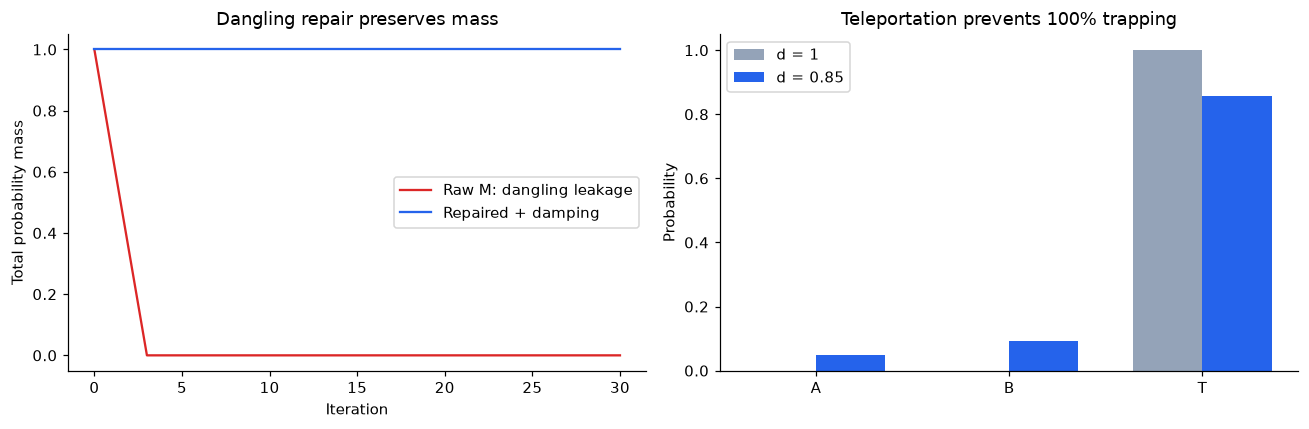

In [21]:
def pagerank_probability(adjacency,damping=0.85,iterations=30,repair_dangling=True):
    # adjacency[v,u] đếm cạnh v→u; chuyển vị để dùng vector cột.
    adjacency = np.asarray(adjacency,dtype=float)
    assert adjacency.ndim == 2 and adjacency.shape[0] == adjacency.shape[1]
    assert (adjacency >= 0).all() and 0 <= damping <= 1
    n = adjacency.shape[0]
    out_degree = adjacency.sum(axis=1)
    transition = np.divide(adjacency,out_degree[:,None],out=np.zeros_like(adjacency),
                           where=out_degree[:,None]>0).T
    if repair_dangling:
        transition[:,out_degree==0] = 1/n
    google = damping*transition + (1-damping)*np.ones((n,n))/n
    rank = np.ones(n)/n
    history = [rank.copy()]
    for _ in range(iterations):
        rank = google @ rank
        history.append(rank.copy())
    return np.asarray(history)

chain = np.array([[0,1,0],[0,0,1],[0,0,0]])
trap = chain.copy()
trap[2,2] = 1
raw_chain = pagerank_probability(chain,1,repair_dangling=False)
fixed_chain = pagerank_probability(chain,0.85)
trapped = pagerank_probability(trap,1)
escapable = pagerank_probability(trap,0.85)
assert np.allclose(raw_chain[:4].sum(axis=1),[1,2/3,1/3,0])
assert np.allclose(fixed_chain.sum(axis=1),1)
assert np.allclose(trapped[-1],[0,0,1])
assert np.allclose(escapable[-1],[0.05,0.0925,0.8575])
display(pd.DataFrame({'account':['A','B','T'],'d=1':trapped[-1],'d=0.85':escapable[-1]}))
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(raw_chain.sum(axis=1),label='Raw M: dangling leakage',color='#dc2626')
axes[0].plot(fixed_chain.sum(axis=1),label='Repaired + damping',color='#2563eb')
axes[0].set(xlabel='Iteration',ylabel='Total probability mass',title='Dangling repair preserves mass')
axes[0].legend()
axes[1].bar(np.arange(3)-0.18,trapped[-1],width=0.36,label='d = 1',color='#94a3b8')
axes[1].bar(np.arange(3)+0.18,escapable[-1],width=0.36,label='d = 0.85',color='#2563eb')
axes[1].set(xticks=np.arange(3),xticklabels=['A','B','T'],ylabel='Probability',
            title='Teleportation prevents 100% trapping')
axes[1].legend()
plt.tight_layout()
plt.show()
checks_passed['PageRank: leakage, damping, mass and worked example'] = True


Nguồn lý thuyết đã dùng trong mục 3.3: Brin & Page (1998), *The Anatomy of a Large-Scale Hypertextual Web Search Engine*; Page et al. (1999), *The PageRank Citation Ranking*; Langville & Meyer (2004), *Deeper Inside PageRank*; Langville & Meyer (2006), *Google’s PageRank and Beyond*. Bản báo cáo: `docs/PartA_Theory.md`.


## 7 · Đối chiếu code và chốt lần chạy PaySim

Cell sau so AST các hàm hiển thị với source production của repo. Code thuật toán ở ngay trong notebook; hạ tầng Windows/Spark dùng module chung. Các bảng kết quả và kiểm tra ở trên được chạy lại từ input, không đọc output cũ để giả lập một lần chạy.


In [22]:
notebook_document = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
visible_functions = {}
for cell in notebook_document['cells']:
    if cell['cell_type'] == 'code':
        for node in ast.parse(''.join(cell['source'])).body:
            if isinstance(node,ast.FunctionDef):
                visible_functions[node.name] = node
source_audit = []
for record in notebook_document['metadata']['graphguard_sources']:
    source = (REPO_ROOT/record['path']).read_text(encoding='utf-8')
    actual_functions = {n.name:n for n in ast.parse(source).body if isinstance(n,ast.FunctionDef)}
    for name in record['functions']:
        assert ast.dump(visible_functions[name],include_attributes=False) == ast.dump(
            actual_functions[name],include_attributes=False), f'Source drift: {record["path"]}:{name}'
    source_audit.append({'module':record['path'],'functions':', '.join(record['functions']),
                         'sha256':hashlib.sha256(source.encode('utf-8')).hexdigest(),'status':'MATCH'})
display(pd.DataFrame(source_audit))
checks_passed['All displayed production functions match repository AST'] = True


,module,functions,sha256,status
0,src/common/graph_utils.py,load_graph,b656fc4d7767fa1a3cc9bdb8e66101b0f6272daf01d586...,MATCH
1,src/motif/toy_cycle.py,"build_toy_graph, find_three_node_cycles, cycle...",44caa76842030eb834f9e854fd7f8b18cd5aabf2498f47...,MATCH
2,src/paysim/motif_finding.py,"find_relays, relay_rows, build_fanin_features,...",c4aee0a2789193e99e30823c051ecad9199b71089db3b6...,MATCH
3,src/motif/evaluation.py,"require_unlabelled, index_transactions, tempor...",bd5de18c8f8b1b1104e623b81644747f1ca1268a37a0cb...,MATCH


In [23]:
assert all(checks_passed.values())
finished_at = datetime.now(timezone.utc)
display(pd.DataFrame([{'check': name, 'status': 'PASS'} for name in checks_passed]))
display(pd.DataFrame([{
    'dataset': 'PaySim', 'scope': 'full',
    'started_utc': started_at.isoformat(), 'finished_utc': finished_at.isoformat(),
    'elapsed_seconds': round(time.perf_counter() - started_clock, 1),
    'review_scope': 'toy motif, Task 3 PaySim, PageRank 3.3',
    **runtime,
}]))
# Dừng Spark trước khi dọn checkpoint tạm ngoài repository.
spark.catalog.clearCache()
spark.stop()
runtime_temp.cleanup()
print('PASS — PaySim: toàn bộ notebook đã chạy, output và hình đã được lưu.')


,check,status
0,Windows Python 3.12 / JDK 17 / dependencies,PASS
1,Toy graph.find: 3 rotations / 1 cycle,PASS
2,PaySim: adversarial relay rules and three-node...,PASS
3,Task 3 PaySim full + exact delivered CSV,PASS
4,"PaySim: causal fan-in, validation selection an...",PASS
5,"PageRank: leakage, damping, mass and worked ex...",PASS
6,All displayed production functions match repos...,PASS


,dataset,scope,started_utc,finished_utc,elapsed_seconds,review_scope,system,python,spark,graphframes,java,master,driver_memory,session_timezone
0,PaySim,full,2026-10-18T16:16:26.858080+00:00,2026-10-18T16:18:17.106643+00:00,110.3,"toy motif, Task 3 PaySim, PageRank 3.3",Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],6g,Asia/Saigon


PASS — PaySim: toàn bộ notebook đã chạy, output và hình đã được lưu.
